<a href="https://colab.research.google.com/github/MarcinPlodzien/deep-learning-for-classical-and-quantum-physics/blob/main/notebooks/lecture-04/lab-010-ising-monte-carlo.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"></a>

<hr/>
# Deep Learning in Classical and Quantum Physics
2026/2027 <br>
**Author:** Marcin Płodzień <br>
**Lab:** 010 
<hr/>

# Lab 010 — Monte Carlo sampling of the 2D Ising model

In Lecture 4 a convolutional neural network (CNN) located the critical temperature $T_c$ of the 2D Ising model from raw spin images.
In this notebook we produce those images ourselves and compare their thermodynamics with Onsager's exact solution (Lecture 4).

We begin with the **Metropolis algorithm** for an $N_x\times N_y$ lattice with periodic boundaries, in a vectorised *checkerboard* form that runs fast in NumPy.
A sampler is only useful if it is used correctly, so we then study how long a chain must run before it forgets its starting point (**equilibration**) and how far apart
stored samples must be to carry independent information (**decorrelation**). With these two answers we generate a **dataset** of configurations on a grid of temperatures
and save it to `data/`, where Lab 011 will find it to train the CNN. Finally we measure the magnetisation, energy, specific heat and susceptibility, compare them with
the exact results of Onsager and Yang, and watch the transition sharpen as the system grows — the logic behind "finding $T_c$".

The lattice size $(N_x, N_y)$ can be changed in Section 5; the default is $20\times20$.

> **How to run this notebook in Google Colab**
> 1. Go to <https://colab.research.google.com> → *File → Upload notebook* (or open it from Google Drive).
> 2. Run cells one by one with **Shift + Enter**. Run them *in order* — later cells use variables defined earlier.
> 3. The required packages (`numpy`, `scipy`, `matplotlib`) are pre-installed in Colab; no `pip install` required.
> 4. The dataset is saved to the folder `data/` in the current working directory (in Colab: `/content`, which is cleared when the runtime is recycled — download the file if you want to keep it).
> 5. If the notebook state becomes inconsistent: *Runtime → Restart session* and run from the top.

In [1]:
import os, time
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import quad
from scipy.special import ellipk

rng = np.random.default_rng(0)          # one random generator for the whole notebook (reproducible results)

# UJ colours used in all plots
UJBlue, UJNavy, DSOrange, UJGray = "#005CA7", "#002B5C", "#D35A05", "#5A6270"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "font.size": 10})

TC = 2.0 / np.log(1.0 + np.sqrt(2.0))   # exact critical temperature (J = k_B = 1), Kramers-Wannier / Onsager
print(f"NumPy {np.__version__};  exact T_c = 2/ln(1+sqrt 2) = {TC:.6f}")

NumPy 2.1.3;  exact T_c = 2/ln(1+sqrt 2) = 2.269185


<hr/>
## 1. The model and its observables

Spins $s_i=\pm1$ sit on an $N_x\times N_y$ square lattice with periodic boundary conditions (a torus), $N=N_xN_y$. The energy is
$$
H(\boldsymbol s) = -J\sum_{\langle i,j\rangle} s_i s_j , \qquad J=1,\ h=0,
$$
where $\langle i,j\rangle$ runs over the $2N$ nearest-neighbour bonds. In equilibrium at temperature $T$ (with $k_B=1$, $\beta=1/T$) the configurations are distributed as
$$
p(\boldsymbol s) = \frac{e^{-\beta H(\boldsymbol s)}}{Z}, \qquad Z=\sum_{\boldsymbol s} e^{-\beta H(\boldsymbol s)} .
$$

The figure below draws a small patch of the lattice. Each disc is a spin: a filled navy disc is $s_i=+1$ and a white disc with an orange rim is $s_i=-1$, the convention of every sketch in this course. A line between two neighbours is a bond, and its contribution $-Js_is_j$ to the energy is $-J$ when the two spins agree (solid blue line, a *satisfied* bond) and $+J$ when they disagree (dashed purple line with a cross, a *broken* bond). The faded discs on the right and on the top are copies of the first column and of the first row: with periodic boundaries the right neighbour of a spin in the last column is the spin in the first column of the same row, and likewise for the top row, so the lattice has no edges and has the topology of a torus. Every broken bond raises the energy by $2J$, so the two uniform configurations, all up and all down, are the ground states.

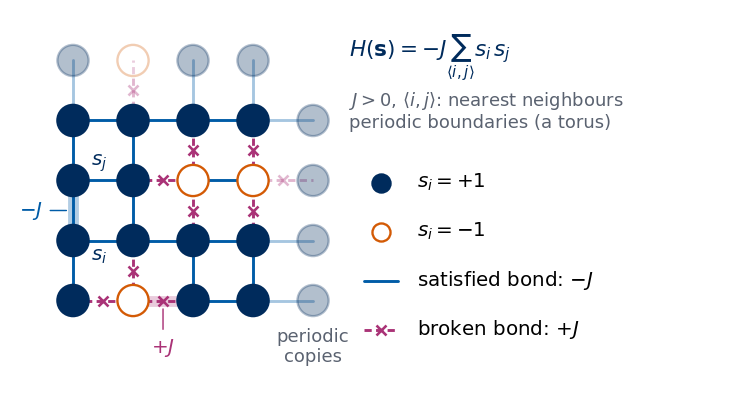

In [ ]:
# Schematic figure; this cell does not depend on any other cell of the notebook.
# Colour convention shared by all sketches of the course:
#   spin s = +1: filled navy disc,   spin s = -1: white disc with an orange rim;
#   satisfied bond: solid blue line, broken (frustrated) bond: dashed purple line marked with a cross.
# The figure is drawn at its physical size on a 16:9 slide (5.5 in = full text width) with 10-12 pt text,
# and shown here at a higher screen resolution.
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

NAVY, ORANGE, BLUE, GRAY, PURPLE, GREEN = "#002B5C", "#D35A05", "#005CA7", "#5A6270", "#AA3377", "#228833"
SKETCH_STYLE = {"font.size": 11, "axes.titlesize": 12, "axes.labelsize": 11, "xtick.labelsize": 10,
                "ytick.labelsize": 10, "legend.fontsize": 10, "figure.dpi": 130, "lines.linewidth": 1.5,
                "axes.spines.top": False, "axes.spines.right": False}

def save_sketch(fig, name, extra_dirs=()):
    # PNG copy for the lecture slides: white background, 300 dpi, included at its physical width
    os.makedirs("../beamer/figures", exist_ok=True)
    for d in ("../beamer/figures",) + tuple(d for d in extra_dirs if os.path.isdir(d)):
        fig.savefig(os.path.join(d, name), dpi=300, facecolor="white")

def draw_spin(ax, x, y, s, r=0.26, sign=False, alpha=1.0, fs=10, lw=1.3):
    # one Ising spin at (x, y): navy disc for s = +1, white disc with orange rim for s = -1 (optionally with "+" / "-")
    face, edge, txt = (NAVY, NAVY, "white") if s > 0 else ("white", ORANGE, ORANGE)
    ax.add_patch(mpatches.Circle((x, y), r, fc=face, ec=edge, lw=lw, alpha=alpha, zorder=4))
    if sign:
        ax.text(x, y, "+" if s > 0 else "−", color=txt, ha="center", va="center", alpha=alpha,
                fontsize=fs, fontweight="bold", zorder=5)

def draw_bond(ax, p, q, broken=False, lw=1.5, alpha=1.0, color=None, cross=True):
    # bond between points p and q: solid blue if satisfied, dashed purple with a cross if broken
    c = color or (PURPLE if broken else BLUE)
    ax.plot([p[0], q[0]], [p[1], q[1]], color=c, lw=lw, ls=(0, (2.5, 1.5)) if broken else "-",
            alpha=alpha, solid_capstyle="round", zorder=2)
    if broken and cross:
        ax.plot((p[0] + q[0]) / 2, (p[1] + q[1]) / 2, marker="x", ms=3.5 * lw, mew=lw * 0.9, color=c, alpha=alpha, zorder=3)

def sketch_ising_model():
    # a 4 x 4 patch of the periodic lattice with a fixed, mostly ordered spin pattern; S[y, x], y = row from the bottom
    L = 4
    S = np.ones((L, L), int)
    S[2, 2] = S[2, 3] = -1                                          # a small domain of two flipped spins
    S[0, 1] = -1                                                    # and one isolated flipped spin
    fig = plt.figure(figsize=(5.5, 2.9))
    ax = fig.add_axes([0.0, 0.0, 0.47, 1.0]); tx = fig.add_axes([0.47, 0.0, 0.53, 1.0]); tx.axis("off")

    # nearest-neighbour bonds inside the patch (right and up neighbours) and the periodic bonds to the ghost copies
    for y in range(L):
        for x in range(L):
            for dx, dy in [(1, 0), (0, 1)]:
                xn, yn = x + dx, y + dy
                s_n = S[yn % L, xn % L]                               # periodic boundaries: index modulo L
                ghost = xn == L or yn == L
                draw_bond(ax, (x, y), (xn, yn), broken=S[y, x] * s_n < 0, lw=1.6, alpha=0.35 if ghost else 1.0)
    # ghost copies of column 1 (right) and row 1 (top): the same spins seen again through the periodic boundary
    for k in range(L):
        draw_spin(ax, L, k, S[k, 0], alpha=0.3); draw_spin(ax, k, L, S[0, k], alpha=0.3)
    for y in range(L):
        for x in range(L):
            draw_spin(ax, x, y, S[y, x])
    ax.text(L, -0.45, "periodic\ncopies", ha="center", va="top", fontsize=10, color=GRAY)

    # one satisfied and one broken bond, annotated with their energies
    i, j = (0, 1), (0, 2)                                           # s_i = s_j = +1: a satisfied bond
    ax.plot(*zip(i, j), color=BLUE, lw=6, alpha=0.3, zorder=1)
    ax.annotate(r"$-J$", xy=(-0.05, 1.5), xytext=(-0.5, 1.5), fontsize=11, ha="right", va="center", color=BLUE,
                arrowprops=dict(arrowstyle="-", color=BLUE, lw=0.8))
    ax.text(i[0] + 0.3, i[1] - 0.1, "$s_i$", fontsize=11, ha="left", va="top", color=NAVY)
    ax.text(j[0] + 0.3, j[1] + 0.1, "$s_j$", fontsize=11, ha="left", va="bottom", color=NAVY)
    k, l = (1, 0), (2, 0)                                           # s = -1 next to s = +1: a broken bond
    ax.plot(*zip(k, l), color=PURPLE, lw=6, alpha=0.25, zorder=1)
    ax.annotate(r"$+J$", xy=(1.5, -0.08), xytext=(1.5, -0.6), fontsize=11, ha="center", va="top", color=PURPLE,
                arrowprops=dict(arrowstyle="-", color=PURPLE, lw=0.8))
    ax.set_xlim(-1.0, L + 0.6); ax.set_ylim(-1.15, L + 0.45); ax.set_aspect("equal"); ax.axis("off")

    # Hamiltonian and legend
    tx.set_xlim(0, 1); tx.set_ylim(0, 1)
    tx.text(0.0, 0.88, r"$H(\mathbf{s})=-J\sum_{\langle i,j\rangle}s_i\,s_j$", fontsize=12, color=NAVY, va="center")
    tx.text(0.0, 0.74, r"$J>0$, $\langle i,j\rangle$: nearest neighbours" "\nperiodic boundaries (a torus)", fontsize=10, color=GRAY, va="center")
    rows = [("spin", +1, r"$s_i=+1$"), ("spin", -1, r"$s_i=-1$"),
            ("bond", False, r"satisfied bond: $-J$"), ("bond", True, r"broken bond: $+J$")]
    for n, (kind, val, label) in enumerate(rows):
        yy = 0.55 - 0.13 * n
        if kind == "spin":
            tx.plot(0.085, yy, "o", ms=10, mfc=NAVY if val > 0 else "white", mec=NAVY if val > 0 else ORANGE, mew=1.3)
        else:
            draw_bond(tx, (0.04, yy), (0.13, yy), broken=val, lw=1.6)
        tx.text(0.18, yy, label, fontsize=11, va="center")
    return fig

with plt.rc_context(SKETCH_STYLE):
    fig = sketch_ising_model()
save_sketch(fig, "sketch_ising_card.png", extra_dirs=("../../Lecture_5/beamer/figures",))
plt.show()


For one configuration we measure the **energy per spin** and the **magnetisation per spin**,
$$
e(\boldsymbol s)=\frac{H(\boldsymbol s)}{N}, \qquad m(\boldsymbol s) = \frac1N\sum_i s_i .
$$
Thermal averages $\langle\cdot\rangle$ are averages over samples drawn from $p(\boldsymbol s)$, and two *fluctuation* quantities follow from the variances:
$$
\begin{aligned}
c &= \frac{N}{T^2}\left(\langle e^2\rangle-\langle e\rangle^2\right) && \text{(specific heat per spin)},\\
\chi &= \frac{N}{T}\left(\langle m^2\rangle-\langle |m|\rangle^2\right) && \text{(susceptibility per spin)}.
\end{aligned}
$$
The absolute value in $\chi$ needs a word of explanation. On a finite lattice the two ordered states $m\approx+M$ and $m\approx-M$ have equal probability, so
$\langle m\rangle=0$ at **every** temperature, and the useful finite-size order parameter is $\langle|m|\rangle$.

We cannot sum over all $2^N$ configurations ($2^{400}$ for $20\times20$), so we **sample** them.

<hr/>
## 2. The Metropolis algorithm

The idea is to build a Markov chain $\boldsymbol s^{(0)}\to\boldsymbol s^{(1)}\to\dots$ whose stationary distribution is $p(\boldsymbol s)$. A sufficient condition on the
transition probabilities $W$ is **detailed balance**:
$$
p(\boldsymbol s)\,W(\boldsymbol s\to\boldsymbol s') = p(\boldsymbol s')\,W(\boldsymbol s'\to\boldsymbol s).
$$
The Metropolis algorithm satisfies it as follows. We propose to flip one spin, $s_i\to-s_i$. Only the four bonds of site $i$ change, so with the local field
$\phi_i=\sum_{j\in\mathrm{nn}(i)}s_j$
$$
\Delta E = E(\boldsymbol s') - E(\boldsymbol s) = 2\,s_i\,\phi_i \in\{-8,-4,0,4,8\}.
$$
The flip is accepted with probability $A=\min\left(1,e^{-\beta\Delta E}\right)$. For $\Delta E>0$ detailed balance holds because
$$
\begin{aligned}
\frac{W(\boldsymbol s\to\boldsymbol s')}{W(\boldsymbol s'\to\boldsymbol s)}
&=\frac{e^{-\beta\Delta E}}{1}
=\frac{e^{-\beta E(\boldsymbol s')}}{e^{-\beta E(\boldsymbol s)}}\\
&=\frac{p(\boldsymbol s')}{p(\boldsymbol s)} ,
\end{aligned}
$$
and the case $\Delta E<0$ is the same equation read backwards. The partition function $Z$ cancels, which is why we never need it.

To make the algorithm fast we colour the lattice like a chessboard. All four neighbours of a black site are white, so the flips of all black sites are
independent of each other and can be carried out **at once**, followed by all white sites. One **sweep**, black half plus white half, is one attempted flip per spin
(one *Monte Carlo step*). With periodic boundaries the chessboard colouring is consistent only if $N_x$ and $N_y$ are **even**.
We also update a whole *batch* of independent lattices (several chains times several temperatures) in one array operation, on arrays of shape `(..., Ny, Nx)`.

The sketch below shows both ideas. On the left, the sites of a $6\times6$ lattice are coloured like a chessboard; the four neighbours of the highlighted dark site are all light, so the new values of all dark spins depend only on light spins and can be drawn at the same time. On the right is a single proposed flip. The central spin $s_i=+1$ has three neighbours up and one down, so its local field is $\phi_i=2$. Before the flip three of its four bonds are satisfied and their energy is $-2J$; after the flip three are broken and their energy is $+2J$. The energy change $\Delta E=2s_i\phi_i=+4J$ is positive, so the flip is accepted only with probability $e^{-4\beta J}$, while the reverse flip, with $\Delta E=-4J$, would always be accepted.

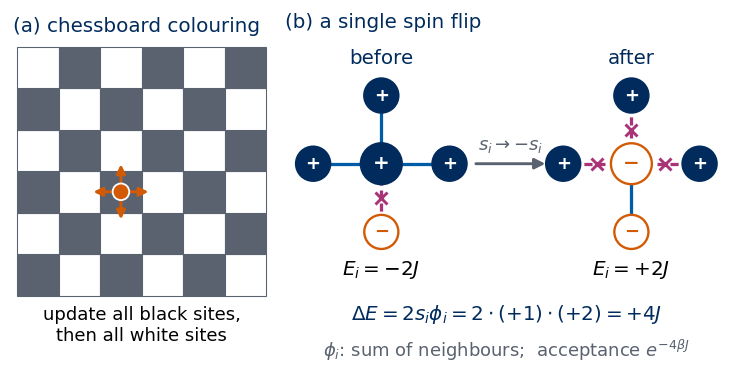

In [ ]:
# Schematic figure; this cell does not depend on any other cell of the notebook.
# Colour convention shared by all sketches of the course:
#   spin s = +1: filled navy disc,   spin s = -1: white disc with an orange rim;
#   satisfied bond: solid blue line, broken (frustrated) bond: dashed purple line marked with a cross.
# The figure is drawn at its physical size on a 16:9 slide (5.5 in = full text width) with 10-12 pt text,
# and shown here at a higher screen resolution.
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

NAVY, ORANGE, BLUE, GRAY, PURPLE, GREEN = "#002B5C", "#D35A05", "#005CA7", "#5A6270", "#AA3377", "#228833"
SKETCH_STYLE = {"font.size": 11, "axes.titlesize": 12, "axes.labelsize": 11, "xtick.labelsize": 10,
                "ytick.labelsize": 10, "legend.fontsize": 10, "figure.dpi": 130, "lines.linewidth": 1.5,
                "axes.spines.top": False, "axes.spines.right": False}

def save_sketch(fig, name, extra_dirs=()):
    # PNG copy for the lecture slides: white background, 300 dpi, included at its physical width
    os.makedirs("../beamer/figures", exist_ok=True)
    for d in ("../beamer/figures",) + tuple(d for d in extra_dirs if os.path.isdir(d)):
        fig.savefig(os.path.join(d, name), dpi=300, facecolor="white")

def draw_spin(ax, x, y, s, r=0.26, sign=False, alpha=1.0, fs=10, lw=1.3):
    # one Ising spin at (x, y): navy disc for s = +1, white disc with orange rim for s = -1 (optionally with "+" / "-")
    face, edge, txt = (NAVY, NAVY, "white") if s > 0 else ("white", ORANGE, ORANGE)
    ax.add_patch(mpatches.Circle((x, y), r, fc=face, ec=edge, lw=lw, alpha=alpha, zorder=4))
    if sign:
        ax.text(x, y, "+" if s > 0 else "−", color=txt, ha="center", va="center", alpha=alpha,
                fontsize=fs, fontweight="bold", zorder=5)

def draw_bond(ax, p, q, broken=False, lw=1.5, alpha=1.0, color=None, cross=True):
    # bond between points p and q: solid blue if satisfied, dashed purple with a cross if broken
    c = color or (PURPLE if broken else BLUE)
    ax.plot([p[0], q[0]], [p[1], q[1]], color=c, lw=lw, ls=(0, (2.5, 1.5)) if broken else "-",
            alpha=alpha, solid_capstyle="round", zorder=2)
    if broken and cross:
        ax.plot((p[0] + q[0]) / 2, (p[1] + q[1]) / 2, marker="x", ms=3.5 * lw, mew=lw * 0.9, color=c, alpha=alpha, zorder=3)

def sketch_checkerboard_and_flip():
    fig = plt.figure(figsize=(5.5, 2.9))
    ax1 = fig.add_axes([0.0, 0.0, 0.36, 0.9]); ax2 = fig.add_axes([0.38, 0.0, 0.62, 0.9])

    # (a) chessboard colouring of a 6 x 6 lattice: a site is "black" if x + y is even
    L = 6
    for y in range(L):
        for x in range(L):
            ax1.add_patch(mpatches.Rectangle((x - 0.5, y - 0.5), 1, 1, fc=GRAY if (x + y) % 2 == 0 else "white", ec=GRAY, lw=0.6))
    c = (2, 2)                                                       # a black site and its four white neighbours
    for dx, dy in [(1, 0), (-1, 0), (0, 1), (0, -1)]:
        ax1.annotate("", xy=(c[0] + 0.75 * dx, c[1] + 0.75 * dy), xytext=c,
                     arrowprops=dict(arrowstyle="-|>", color=ORANGE, lw=1.6, mutation_scale=10))
    ax1.add_patch(mpatches.Circle(c, 0.2, fc=ORANGE, ec="white", lw=1, zorder=5))
    ax1.text((L - 1) / 2, -0.75, "update all black sites,\nthen all white sites", ha="center", va="top", fontsize=10)
    ax1.set_title("(a) chessboard colouring", fontsize=11, color=NAVY, loc="left")
    ax1.set_xlim(-0.6, L - 0.4); ax1.set_ylim(-2.3, L - 0.4); ax1.set_aspect("equal"); ax1.axis("off")

    # (b) one proposed flip: centre spin s_i = +1 with neighbours (+1, +1, +1, -1), local field phi_i = 2
    nb = {(1, 0): +1, (0, 1): +1, (-1, 0): +1, (0, -1): -1}
    phi = sum(nb.values())
    for x0, s_c, label in [(0.0, +1, "before"), (4.4, -1, "after")]:
        for (dx, dy), s in nb.items():
            draw_bond(ax2, (x0, 0), (x0 + 1.2 * dx, 1.2 * dy), broken=s_c * s < 0, lw=1.8)
            draw_spin(ax2, x0 + 1.2 * dx, 1.2 * dy, s, r=0.3, sign=True)
        draw_spin(ax2, x0, 0, s_c, r=0.36, sign=True, fs=11)
        e_loc = -sum(s_c * s for s in nb.values())                   # energy of the four bonds of site i (J = 1)
        ax2.text(x0, 1.75, label, ha="center", fontsize=11, color=NAVY)
        ax2.text(x0, -1.95, f"$E_i={e_loc:+d}J$", ha="center", fontsize=11)
    ax2.annotate("", xy=(2.95, 0), xytext=(1.6, 0), arrowprops=dict(arrowstyle="-|>", color=GRAY, lw=1.6, mutation_scale=12))
    ax2.text(2.27, 0.25, r"$s_i\to{-s_i}$", ha="center", fontsize=10, color=GRAY)
    ax2.text(2.2, -2.75, rf"$\Delta E=2s_i\phi_i=2\cdot(+1)\cdot({phi:+d})={2 * phi:+d}J$", ha="center", fontsize=11, color=NAVY)
    ax2.text(2.2, -3.4, r"$\phi_i$: sum of neighbours;  acceptance $e^{-4\beta J}$", ha="center", fontsize=10, color=GRAY)
    ax2.set_title("(b) a single spin flip", fontsize=11, color=NAVY, loc="left")
    ax2.set_xlim(-1.7, 6.1); ax2.set_ylim(-3.7, 2.2); ax2.set_aspect("equal"); ax2.axis("off")
    return fig

with plt.rc_context(SKETCH_STYLE):
    fig = sketch_checkerboard_and_flip()
save_sketch(fig, "sketch_ising_checkerboard_flip.png")
plt.show()


In [2]:
def show_spins(ax, s):
    # Draw a spin configuration as a black/white image with a thin frame.
    ax.imshow(s, cmap="gray", vmin=-1, vmax=1)
    ax.set_xticks([]); ax.set_yticks([])
    for sp in ax.spines.values():
        sp.set_visible(True); sp.set_color(UJGray); sp.set_linewidth(0.6)

def checkerboard_masks(Ny, Nx):
    # Boolean masks of the 'black' and 'white' sites of an Ny x Nx chessboard.
    assert Nx % 2 == 0 and Ny % 2 == 0, "checkerboard updates with periodic boundaries need even Nx and Ny"
    y, x = np.indices((Ny, Nx))
    black = (x + y) % 2 == 0
    return black, ~black

def local_field(s):
    # Sum of the four nearest neighbours of every site; np.roll implements the periodic boundaries.
    return (np.roll(s, 1, axis=-1) + np.roll(s, -1, axis=-1)
            + np.roll(s, 1, axis=-2) + np.roll(s, -1, axis=-2))

def metropolis_sweep(s, beta, masks, rng):
    # One Monte Carlo sweep (in place). s: float32 array (..., Ny, Nx) of +-1; beta broadcastable to s.
    for mask in masks:                                   # first all black sites, then all white sites
        dE = 2.0 * s * local_field(s)                    # energy change if the spin is flipped
        accept = rng.random(s.shape, dtype=np.float32) < np.exp(-beta * dE)   # dE <= 0 gives exp >= 1: always accepted
        s[...] = np.where(mask & accept, -s, s)
    return s

def energy_per_spin(s):
    # e = H/N = -(1/N) sum over bonds; each bond counted once via the right and down neighbours.
    bonds = s * np.roll(s, -1, axis=-1) + s * np.roll(s, -1, axis=-2)
    return -bonds.mean(axis=(-2, -1))

def magnetisation_per_spin(s):
    return s.mean(axis=(-2, -1))

Before relying on the sampler we test it where the exact answer is available. On a small $4\times4$ lattice we can enumerate all $2^{16}=65\,536$ configurations
and compute $\langle e\rangle$ and $\langle|m|\rangle$ *exactly*; the sampler must reproduce them within its statistical error. In the output the Monte Carlo values agree
with the exact ones to within about two error bars at all three temperatures.

In [3]:
def exact_small(Ny, Nx, T):
    # Exact averages by brute-force enumeration of all 2^(Nx*Ny) configurations.
    n = Nx * Ny
    idx = np.arange(2**n, dtype=np.int64)
    s = (((idx[:, None] >> np.arange(n)) & 1) * 2 - 1).reshape(-1, Ny, Nx).astype(np.float32)
    e, m = energy_per_spin(s), magnetisation_per_spin(s)
    w = np.exp(-n * (e - e.min()) / T)                    # Boltzmann weights (shifted for numerical safety)
    w /= w.sum()
    return (w * e).sum(), (w * np.abs(m)).sum()

masks4 = checkerboard_masks(4, 4)
for T in (1.5, 2.5, 3.5):
    s = np.ones((2000, 4, 4), np.float32)                 # 2000 independent chains
    for _ in range(300):
        metropolis_sweep(s, 1.0 / T, masks4, rng)
    e_mc, m_mc = [], []
    for _ in range(200):                                  # 200 more sweeps, measuring after each
        metropolis_sweep(s, 1.0 / T, masks4, rng)
        e_mc.append(energy_per_spin(s)); m_mc.append(np.abs(magnetisation_per_spin(s)))
    e_mc, m_mc = np.array(e_mc), np.array(m_mc)
    e_ex, m_ex = exact_small(4, 4, T)
    err = lambda a: a.mean(axis=0).std() / np.sqrt(a.shape[1])   # error bar from the spread between chains
    print(f"T = {T}:  <e> MC = {e_mc.mean():+.4f} +- {err(e_mc):.4f}   exact = {e_ex:+.4f}   |"
          f"  <|m|> MC = {m_mc.mean():.4f} +- {err(m_mc):.4f}   exact = {m_ex:.4f}")

T = 1.5:  <e> MC = -1.9500 +- 0.0003   exact = -1.9506   |  <|m|> MC = 0.9860 +- 0.0001   exact = 0.9862


T = 2.5:  <e> MC = -1.3776 +- 0.0014   exact = -1.3791   |  <|m|> MC = 0.7643 +- 0.0007   exact = 0.7647


T = 3.5:  <e> MC = -0.7777 +- 0.0011   exact = -0.7762   |  <|m|> MC = 0.4887 +- 0.0006   exact = 0.4884


<hr/>
## 3. Equilibration time

A chain starts from an arbitrary configuration, which is *not* typical for $p(\boldsymbol s)$, so we discard the first sweeps (the **burn-in**) until the
observables stop drifting. Two starting points are natural: a **cold start** with all spins up (the $T=0$ ground state) and a **hot start** with random spins
($T=\infty$). When chains from both starts reach the same values, they have very likely forgotten where they began. The cell below follows $|m|$ and $e$ along
1500 sweeps for four chains of each kind at $T = 1.8$, $2.27$ and $3.0$, on a logarithmic time axis.

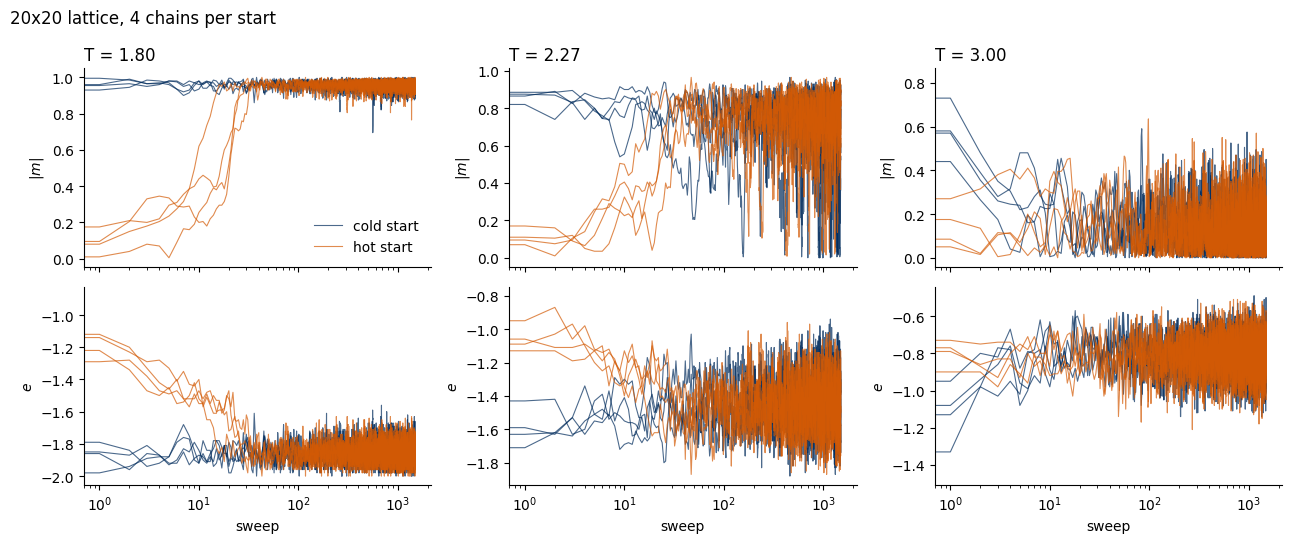

In [4]:
Lx_demo = 20
masks_demo = checkerboard_masks(Lx_demo, Lx_demo)
T_demo = np.array([1.8, 2.27, 3.0], dtype=np.float32)
n_sweeps = 1500
n_chains_demo = 4

starts = {"cold": np.ones((n_chains_demo, len(T_demo), Lx_demo, Lx_demo), np.float32),
          "hot":  rng.choice(np.array([-1, 1], np.float32), size=(n_chains_demo, len(T_demo), Lx_demo, Lx_demo))}
series = {}
for name, s in starts.items():
    beta = (1.0 / T_demo)[None, :, None, None]
    m_t, e_t = [], []
    for t in range(n_sweeps):
        metropolis_sweep(s, beta, masks_demo, rng)
        m_t.append(magnetisation_per_spin(s)); e_t.append(energy_per_spin(s))
    series[name] = (np.array(m_t), np.array(e_t), s.copy())      # arrays of shape (sweep, chain, T)

fig, axes = plt.subplots(2, 3, figsize=(13, 5.5), sharex=True)
for k, T in enumerate(T_demo):
    for name, col in (("cold", UJNavy), ("hot", DSOrange)):
        m_t, e_t, _ = series[name]
        for c in range(n_chains_demo):
            axes[0, k].plot(np.abs(m_t[:, c, k]), color=col, lw=0.8, alpha=0.7, label=f"{name} start" if c == 0 else None)
            axes[1, k].plot(e_t[:, c, k], color=col, lw=0.8, alpha=0.7)
    axes[0, k].set_title(f"T = {T:.2f}", loc="left")
    axes[0, k].set_ylabel(r"$|m|$"); axes[1, k].set_ylabel(r"$e$"); axes[1, k].set_xlabel("sweep")
    axes[0, k].set_xscale("log"); axes[1, k].set_xscale("log")
axes[0, 0].legend(frameon=False)
fig.suptitle(f"{Lx_demo}x{Lx_demo} lattice, {n_chains_demo} chains per start", x=0.01, ha="left")
fig.tight_layout(); plt.show()

At $T=3.0$, in the disordered phase, both starts merge after a few sweeps. At $T=1.8$, in the ordered phase, a hot start must *coarsen*: domains of up and down
spins grow and merge. Sometimes two domains wrap around the torus as **stripes**, separated by two flat domain walls. A flat wall costs energy but has no curvature to
shrink it, so it can survive for a very long time, and such a chain would sit at $|m|$ well below the ordered value, with a slightly higher energy. Whether this happens
depends on the random seed; rerun the cell with another seed or more chains and look at the final snapshots below. At $T\approx T_c$ the fluctuations are large and slow,
a phenomenon called **critical slowing down**.

For the dataset we therefore use a **cold start**: below $T_c$ it is already close to equilibrium, and above $T_c$ it melts quickly.

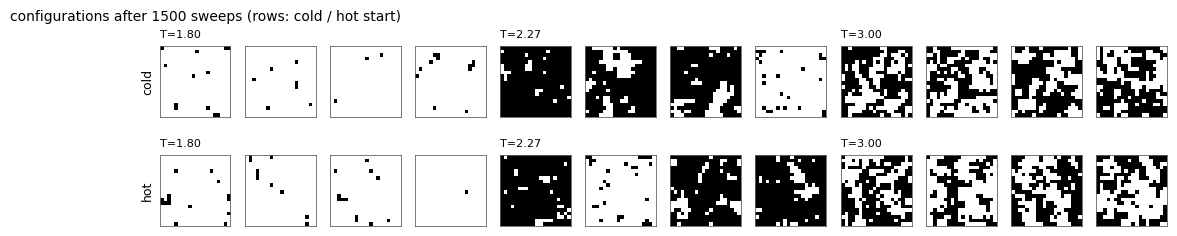

In [5]:
fig, axes = plt.subplots(2, 3 * n_chains_demo, figsize=(13, 2.6))
for r, name in enumerate(("cold", "hot")):
    s_final = series[name][2]
    for k in range(len(T_demo)):
        for c in range(n_chains_demo):
            ax = axes[r, k * n_chains_demo + c]
            show_spins(ax, s_final[c, k])
            if c == 0: ax.set_title(f"T={T_demo[k]:.2f}", fontsize=8, loc="left")
    axes[r, 0].set_ylabel(name, fontsize=9)
fig.suptitle(f"configurations after {n_sweeps} sweeps (rows: cold / hot start)", x=0.01, ha="left", fontsize=10)
plt.show()

<hr/>
## 4. Autocorrelation of the chain

Consecutive configurations of a Markov chain are **correlated**, because one sweep changes only part of the lattice. For an observable $O$ (here $|m|$)
the normalised autocorrelation function is
$$
\begin{aligned}
C_O(t) &= \frac{\langle O_{t_0}O_{t_0+t}\rangle - \langle O\rangle^2}{\langle O^2\rangle-\langle O\rangle^2},\\
C_O(0) &= 1,
\end{aligned}
$$
and the **integrated autocorrelation time** is
$$
\tau_{\rm int} = \frac12 + \sum_{t\geq1} C_O(t).
$$
Out of $n$ consecutive measurements only about $n/(2\tau_{\rm int})$ are effectively independent. We sum $C_O(t)$ up to the first time it drops
below zero, since beyond that point the estimate is noise. Two remedies follow, and we use both: store samples only every $2\tau_{\rm int}$ sweeps or more,
and run **many independent chains**. The cell below measures $\tau_{\rm int}$ at five temperatures across the transition.

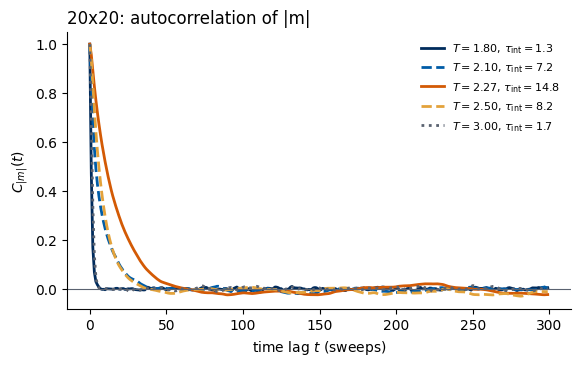

T = 1.80:  tau_int =    1.3 sweeps
T = 2.10:  tau_int =    7.2 sweeps
T = 2.27:  tau_int =   14.8 sweeps
T = 2.50:  tau_int =    8.2 sweeps
T = 3.00:  tau_int =    1.7 sweeps


In [6]:
def autocorrelation(x):
    # x: (time, chains). Normalised autocorrelation averaged over chains, computed with the FFT.
    x = x - x.mean(axis=0)
    n = x.shape[0]
    f = np.fft.rfft(x, n=2 * n, axis=0)
    acf = np.fft.irfft(f * np.conj(f), axis=0)[:n].mean(axis=1)
    return acf / acf[0]

def tau_int(acf):
    cut = np.argmax(acf < 0) if np.any(acf < 0) else len(acf)   # stop at the first negative value
    return 0.5 + acf[1:cut].sum()

T_acf = np.array([1.8, 2.1, 2.27, 2.5, 3.0], dtype=np.float32)
n_chains_acf, n_eq_acf, n_meas_acf = 32, 1000, 3000
s = np.ones((n_chains_acf, len(T_acf), 20, 20), np.float32)
beta = (1.0 / T_acf)[None, :, None, None]
for _ in range(n_eq_acf):
    metropolis_sweep(s, beta, masks_demo, rng)
absm = np.empty((n_meas_acf, n_chains_acf, len(T_acf)), np.float32)
for t in range(n_meas_acf):
    metropolis_sweep(s, beta, masks_demo, rng)
    absm[t] = np.abs(magnetisation_per_spin(s))

fig, ax = plt.subplots(figsize=(6.5, 3.6))
acf_colours = [UJNavy, UJBlue, DSOrange, "#E3A23B", UJGray]
acf_styles = ["-", "--", "-", "--", ":"]
taus = {}
for k, T in enumerate(T_acf):
    acf = autocorrelation(absm[:, :, k])
    taus[T] = tau_int(acf)
    ax.plot(acf[:300], color=acf_colours[k], ls=acf_styles[k], lw=2, label=fr"$T={T:.2f}$, $\tau_{{\rm int}}={taus[T]:.1f}$")
ax.axhline(0, color=UJGray, lw=0.8)
ax.set_xlabel("time lag $t$ (sweeps)"); ax.set_ylabel(r"$C_{|m|}(t)$"); ax.legend(frameon=False, fontsize=8)
ax.set_title("20x20: autocorrelation of |m|", loc="left"); plt.show()
for T, tau in taus.items():
    print(f"T = {T:.2f}:  tau_int = {tau:6.1f} sweeps")

The autocorrelation time is largest close to $T_c$, $14.8$ sweeps at $T=2.27$ against $1.3$ at $T=1.8$ and $1.7$ at $T=3.0$. This is critical slowing down again:
near $T_c$ the correlated regions are large, and a local single-spin update needs many sweeps to change them. Cluster algorithms such as that of Wolff [U. Wolff, Phys. Rev. Lett. **62**, 361 (1989), [doi:10.1103/PhysRevLett.62.361](https://doi.org/10.1103/PhysRevLett.62.361)] largely avoid the problem;
we stay with Metropolis because it is simple and is the algorithm of the Lecture Notes.

In the dataset below we run 20 independent chains per temperature and store a configuration every `n_between` sweeps. Compared with the values of $\tau_{\rm int}$
printed above, the stored samples of one chain are practically independent far from $T_c$; close to $T_c$ they are not fully independent, but the 20 chains are.

<hr/>
## 5. The dataset

We sample a grid of temperatures from $T=1.0$ to $T=3.5$ in steps of $0.05$. All temperatures and all chains are updated together as one array of shape
`(chains, temperatures, Ny, Nx)`.

The Ising energy is symmetric under a **global spin flip** $\boldsymbol s\to-\boldsymbol s$, but a cold start puts every low-temperature chain into the $m>0$ state,
where it stays on our time scales. We restore the symmetry exactly by flipping each stored configuration with probability $1/2$; otherwise a network could learn
the trivial rule "black means ordered".

The lattice size is set by `Nx`, `Ny` in the next cell; both must be even.

In [7]:
Nx, Ny = 20, 20                                        # lattice size (even numbers)
temperatures = np.round(np.arange(1.0, 3.5 + 1e-9, 0.05), 2)
n_chains   = 20                                        # independent chains per temperature
n_samples  = 10                                        # stored configurations per chain  -> 200 per temperature
n_equil    = 1000                                      # burn-in sweeps
n_between  = 20                                        # sweeps between stored configurations

def generate_dataset(Nx, Ny, temperatures, n_chains, n_samples, n_equil, n_between, rng):
    masks = checkerboard_masks(Ny, Nx)
    beta = (1.0 / temperatures.astype(np.float32))[None, :, None, None]
    s = np.ones((n_chains, len(temperatures), Ny, Nx), np.float32)       # cold start
    for _ in range(n_equil):
        metropolis_sweep(s, beta, masks, rng)
    stored = np.empty((n_samples, n_chains, len(temperatures), Ny, Nx), np.int8)
    for k in range(n_samples):
        for _ in range(n_between):
            metropolis_sweep(s, beta, masks, rng)
        stored[k] = s
    configs = stored.transpose(2, 0, 1, 3, 4).reshape(len(temperatures), n_samples * n_chains, Ny, Nx)
    flip = rng.choice(np.array([-1, 1], np.int8), size=configs.shape[:2])  # random global spin flip
    return configs * flip[:, :, None, None]

t0 = time.time()
configs = generate_dataset(Nx, Ny, temperatures, n_chains, n_samples, n_equil, n_between, rng)
print(f"configs: shape {configs.shape} (temperatures, samples, Ny, Nx), dtype {configs.dtype}, "
      f"generated in {time.time() - t0:.1f} s")

os.makedirs("data", exist_ok=True)
path = f"data/ising_Nx{Nx}_Ny{Ny}.npz"
np.savez_compressed(path, configs=configs, T=temperatures, Nx=Nx, Ny=Ny,
                    n_equil=n_equil, n_between=n_between, n_chains=n_chains)
print(f"saved to {path}  ({os.path.getsize(path) / 1e6:.2f} MB)")

configs: shape (51, 200, 20, 20) (temperatures, samples, Ny, Nx), dtype int8, generated in 20.5 s


saved to data/ising_Nx20_Ny20.npz  (0.36 MB)


<hr/>
## 6. Spin configurations across the transition

Before looking at the samples it helps to know what to expect. The schematic below shows idealised configurations of an $8\times8$ lattice in the three regimes, with the magnetisation per spin $m=\frac1N\sum_is_i$ printed above each panel. Below $T_c$ almost all spins are aligned, either up or down, with a few thermally flipped spins; the two ordered states have the same energy and opposite magnetisation $m\approx\pm M$. Near $T_c$ the lattice is a patchwork of up and down domains of all sizes, and $m$ fluctuates strongly from one configuration to the next. Above $T_c$, in the disordered phase called the paramagnet, the spins are nearly independent and $m$ is close to zero. The magnetisation is the order parameter of the model: it is non-zero in the ordered phase and zero in the paramagnet.

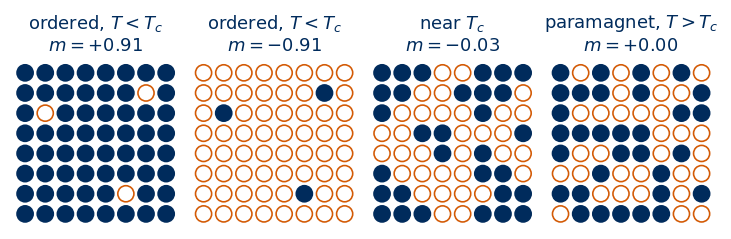

In [ ]:
# Schematic figure; this cell does not depend on any other cell of the notebook.
# Colour convention shared by all sketches of the course:
#   spin s = +1: filled navy disc,   spin s = -1: white disc with an orange rim;
#   satisfied bond: solid blue line, broken (frustrated) bond: dashed purple line marked with a cross.
# The figure is drawn at its physical size on a 16:9 slide (5.5 in = full text width) with 10-12 pt text,
# and shown here at a higher screen resolution.
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

NAVY, ORANGE, BLUE, GRAY, PURPLE, GREEN = "#002B5C", "#D35A05", "#005CA7", "#5A6270", "#AA3377", "#228833"
SKETCH_STYLE = {"font.size": 11, "axes.titlesize": 12, "axes.labelsize": 11, "xtick.labelsize": 10,
                "ytick.labelsize": 10, "legend.fontsize": 10, "figure.dpi": 130, "lines.linewidth": 1.5,
                "axes.spines.top": False, "axes.spines.right": False}

def save_sketch(fig, name, extra_dirs=()):
    # PNG copy for the lecture slides: white background, 300 dpi, included at its physical width
    os.makedirs("../beamer/figures", exist_ok=True)
    for d in ("../beamer/figures",) + tuple(d for d in extra_dirs if os.path.isdir(d)):
        fig.savefig(os.path.join(d, name), dpi=300, facecolor="white")

def draw_spin(ax, x, y, s, r=0.26, sign=False, alpha=1.0, fs=10, lw=1.3):
    # one Ising spin at (x, y): navy disc for s = +1, white disc with orange rim for s = -1 (optionally with "+" / "-")
    face, edge, txt = (NAVY, NAVY, "white") if s > 0 else ("white", ORANGE, ORANGE)
    ax.add_patch(mpatches.Circle((x, y), r, fc=face, ec=edge, lw=lw, alpha=alpha, zorder=4))
    if sign:
        ax.text(x, y, "+" if s > 0 else "−", color=txt, ha="center", va="center", alpha=alpha,
                fontsize=fs, fontweight="bold", zorder=5)

def draw_bond(ax, p, q, broken=False, lw=1.5, alpha=1.0, color=None, cross=True):
    # bond between points p and q: solid blue if satisfied, dashed purple with a cross if broken
    c = color or (PURPLE if broken else BLUE)
    ax.plot([p[0], q[0]], [p[1], q[1]], color=c, lw=lw, ls=(0, (2.5, 1.5)) if broken else "-",
            alpha=alpha, solid_capstyle="round", zorder=2)
    if broken and cross:
        ax.plot((p[0] + q[0]) / 2, (p[1] + q[1]) / 2, marker="x", ms=3.5 * lw, mew=lw * 0.9, color=c, alpha=alpha, zorder=3)

def sketch_ising_phases_configs():
    L = 8
    rng = np.random.default_rng(3)                                 # fixed seed: the same schematic every time
    ordered = np.ones((L, L), int)
    ordered[[1, 5, 6], [5, 1, 6]] = -1                              # a few thermally flipped spins
    # near T_c: domains of many sizes, from single spins to regions comparable with the lattice
    critical = np.array([[ 1,  1,  1, -1, -1,  1,  1,  1],
                         [ 1,  1, -1, -1, -1, -1,  1,  1],
                         [ 1, -1, -1, -1, -1,  1,  1, -1],
                         [-1, -1, -1,  1, -1,  1, -1, -1],
                         [-1, -1,  1,  1, -1, -1, -1,  1],
                         [ 1, -1, -1, -1, -1,  1, -1, -1],
                         [ 1,  1, -1, -1,  1,  1,  1, -1],
                         [ 1,  1,  1, -1, -1,  1,  1,  1]])
    disordered = rng.permutation(np.repeat([1, -1], L * L // 2)).reshape(L, L)   # exactly half up: m = 0
    panels = [(ordered, r"ordered, $T<T_c$"), (-ordered, r"ordered, $T<T_c$"),
              (critical, r"near $T_c$"), (disordered, r"paramagnet, $T>T_c$")]

    fig, axes = plt.subplots(1, 4, figsize=(5.5, 1.95))
    fig.subplots_adjust(left=0.01, right=0.99, bottom=0.01, top=0.78, wspace=0.08)
    for ax, (S, title) in zip(axes, panels):
        for (yy, xx), s in np.ndenumerate(S):
            draw_spin(ax, xx, yy, s, r=0.4, lw=0.9)
        ax.set_title(f"{title}\n$m={S.mean():+.2f}$", fontsize=10, color=NAVY)
        ax.set_xlim(-0.6, L - 0.4); ax.set_ylim(-0.6, L - 0.4); ax.set_aspect("equal"); ax.axis("off")
    return fig

with plt.rc_context(SKETCH_STYLE):
    fig = sketch_ising_phases_configs()
save_sketch(fig, "sketch_ising_phase_configs.png", extra_dirs=("../../Lecture_5/beamer/figures",))
plt.show()


The figure shows three stored configurations at each of seven temperatures, from deep in the ordered phase to well above $T_c$.

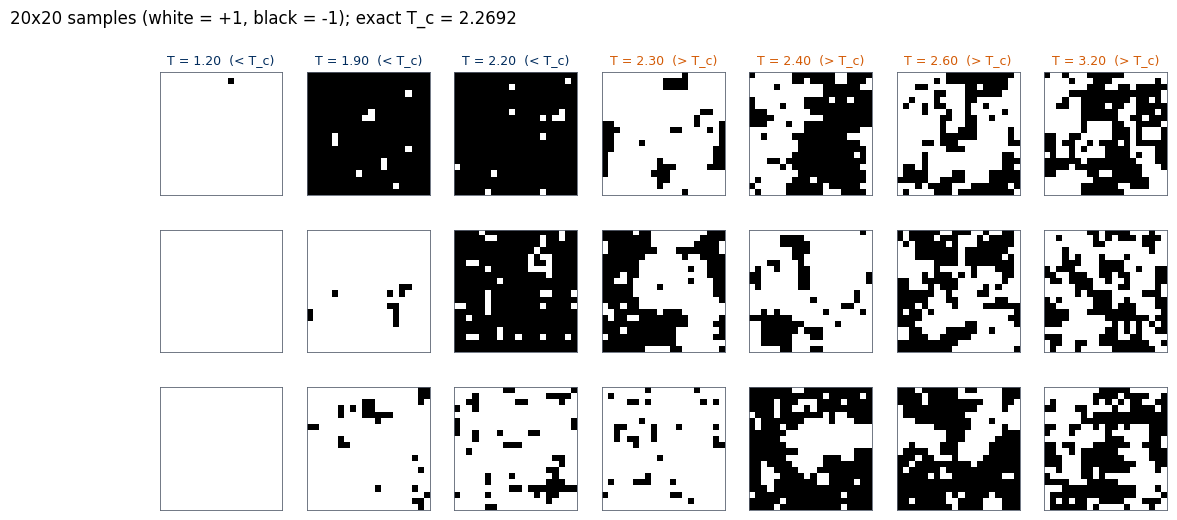

In [8]:
show_T = [1.2, 1.9, 2.2, 2.3, 2.4, 2.6, 3.2]
fig, axes = plt.subplots(3, len(show_T), figsize=(13, 5.8))
for k, T in enumerate(show_T):
    i = np.argmin(np.abs(temperatures - T))
    for r in range(3):
        ax = axes[r, k]
        show_spins(ax, configs[i, r * 37])
    axes[0, k].set_title(f"T = {temperatures[i]:.2f}" + ("  (< T_c)" if temperatures[i] < TC else "  (> T_c)"),
                         fontsize=9, color=UJNavy if temperatures[i] < TC else DSOrange)
fig.suptitle(f"{Nx}x{Ny} samples (white = +1, black = -1); exact T_c = {TC:.4f}", x=0.01, ha="left")
plt.show()

Close to $T_c$ (the columns $2.2$–$2.4$) configurations from the two phases are hard to tell apart by eye: we see clusters of all sizes. This
is precisely the region the CNN of Lab 011 will *not* see during training.
<hr/>
## 7. Thermodynamics of the samples

To judge the samples we need the exact results for the infinite lattice ($J=1$, $K=\beta J$). Onsager's free energy (1944), with $\kappa = 2\sinh 2K/\cosh^2 2K$, is
$$
\begin{aligned}
-\beta f = \ln Z/N &= \ln\left(2\cosh 2K\right)\\
&\quad + \frac{1}{2\pi}\int_0^\pi d\phi\, \ln\frac{1+\sqrt{1-\kappa^2\sin^2\phi}}{2}.
\end{aligned}
$$
The energy per spin $u = -\partial(\ln Z/N)/\partial\beta$ evaluates to
$$
\begin{aligned}
u &= -\coth 2K\left[1+\frac{2}{\pi}\left(2\tanh^2 2K-1\right)K_1(\kappa)\right],\\
K_1(\kappa) &= \int_0^{\pi/2}\frac{d\phi}{\sqrt{1-\kappa^2\sin^2\phi}},
\end{aligned}
$$
and the spontaneous magnetisation (announced by Onsager in 1949, proved by Yang in 1952) is
$$
M = \left[1-\sinh^{-4}2K\right]^{1/8} \ \ (T<T_c), \qquad M=0 \ \ (T>T_c).
$$
Before using the formula for $u$ we verify it against a numerical derivative of the free-energy integral; note that SciPy's `ellipk(m)` uses the
parameter $m=\kappa^2$. The two agree to at least seven decimal places, and at $T_c$ the formula gives $u=-\sqrt2$. The second cell then compares the four measured quantities with these curves.

In [9]:
def lnZ_per_spin(T):
    K = 1.0 / T
    kap = 2 * np.sinh(2 * K) / np.cosh(2 * K) ** 2
    integrand = lambda p: np.log(0.5 * (1 + np.sqrt(max(0.0, 1 - kap**2 * np.sin(p) ** 2))))
    I, _ = quad(integrand, 0, np.pi, points=[np.pi / 2], limit=200)
    return np.log(2 * np.cosh(2 * K)) + I / (2 * np.pi)

def u_exact(T):
    K = 1.0 / np.asarray(T, float)
    kap = 2 * np.sinh(2 * K) / np.cosh(2 * K) ** 2
    return -1 / np.tanh(2 * K) * (1 + 2 / np.pi * (2 * np.tanh(2 * K) ** 2 - 1) * ellipk(kap**2))

def M_exact(T):
    T = np.asarray(T, float)
    out = np.zeros_like(T)
    low = T < TC
    out[low] = (1 - np.sinh(2 / T[low]) ** -4) ** 0.125
    return out

for T in (1.5, 2.0, 2.6, 3.5):                        # u from the formula vs -d lnZ / d beta (central difference)
    b, h = 1 / T, 1e-5
    u_num = -(lnZ_per_spin(1 / (b + h)) - lnZ_per_spin(1 / (b - h))) / (2 * h)
    print(f"T = {T}:  formula u = {u_exact(T):+.8f}   -d lnZ/d beta = {u_num:+.8f}")
print(f"u(T_c) from the formula: {u_exact(TC * (1 + 1e-9)):.6f};  -sqrt(2) = {-np.sqrt(2):.6f}")

T = 1.5:  formula u = -1.95111657   -d lnZ/d beta = -1.95111657
T = 2.0:  formula u = -1.74556458   -d lnZ/d beta = -1.74556457
T = 2.6:  formula u = -1.02829364   -d lnZ/d beta = -1.02829364
T = 3.5:  formula u = -0.66012173   -d lnZ/d beta = -0.66012173
u(T_c) from the formula: -1.414214;  -sqrt(2) = -1.414214


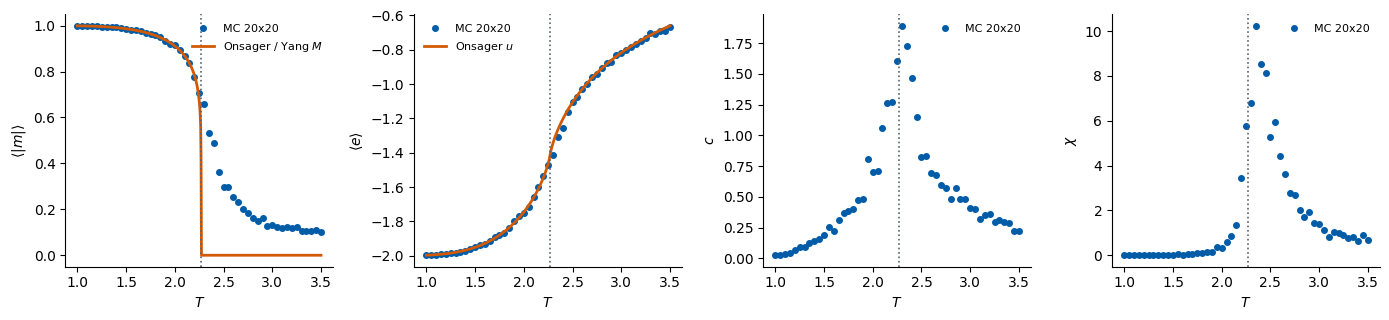

peak of c   at T = 2.30
peak of chi at T = 2.35      exact T_c = 2.2692


In [10]:
cf = configs.astype(np.float32)
N = Nx * Ny
e_s = energy_per_spin(cf)                             # shape (temperatures, samples)
m_s = magnetisation_per_spin(cf)
E_mean, absM_mean = e_s.mean(1), np.abs(m_s).mean(1)
C_heat = N * e_s.var(1) / temperatures**2
chi = N * ((m_s**2).mean(1) - np.abs(m_s).mean(1) ** 2) / temperatures

Tf = np.linspace(1.0, 3.5, 600)
fig, axes = plt.subplots(1, 4, figsize=(14, 3.3))
panels = [(absM_mean, r"$\langle|m|\rangle$", M_exact(Tf), "Onsager / Yang $M$"),
          (E_mean, r"$\langle e\rangle$", u_exact(Tf), "Onsager $u$"),
          (C_heat, r"$c$", None, None),
          (chi, r"$\chi$", None, None)]
for ax, (y, lab, yex, exlab) in zip(axes, panels):
    ax.plot(temperatures, y, "o", ms=4, color=UJBlue, label=f"MC {Nx}x{Ny}")
    if yex is not None:
        ax.plot(Tf, yex, color=DSOrange, lw=2, label=exlab)
    ax.axvline(TC, color=UJGray, ls=":", lw=1.2)
    ax.set_xlabel("$T$"); ax.set_ylabel(lab)
    ax.legend(frameon=False, fontsize=8)
fig.tight_layout(); plt.show()

i_c, i_chi = np.argmax(C_heat), np.argmax(chi)
print(f"peak of c   at T = {temperatures[i_c]:.2f}")
print(f"peak of chi at T = {temperatures[i_chi]:.2f}      exact T_c = {TC:.4f}")

Far from $T_c$ the Monte Carlo points lie on the exact curves: a $20\times20$ lattice is already "large" there, because the correlation length is short.
Near $T_c$ the finite lattice deviates. $\langle|m|\rangle$ does not drop to zero at $T_c$ but has a smooth tail above it, whereas the exact $M$ has an infinite slope at
$T_c$, which no finite system can have. Likewise $c$ and $\chi$ have **finite peaks** instead of divergences, at $T = 2.30$ and $T = 2.35$ — close to $T_c = 2.2692$, but not at it.

The measurements of this section fit into the phase diagram of the model, drawn below for an infinite lattice. A phase diagram is a map of the control parameters, here the temperature $T$ and a magnetic field $h$ that adds $-h\sum_is_i$ to the energy, divided into regions with qualitatively different behaviour, the phases, and the lines between them, the phase transitions.

The type of a transition is read off from the free energy per spin $f(T,h)$ and its derivatives, such as the magnetisation $m=-\partial f/\partial h$ and the energy. At a **first-order** transition a first derivative of $f$ jumps: the order parameter changes discontinuously and the two phases coexist at the transition. At a **continuous** (or second-order) transition the first derivatives are continuous, the order parameter goes to zero continuously, and the correlation length $\xi$, the distance over which spins influence each other, diverges as a power of the distance to the critical point, $\xi\sim|T-T_c|^{-\nu}$; second derivatives such as the specific heat and the susceptibility then diverge or have a cusp.

In panel (a) the segment $h=0$, $T<T_c$ is a line of first-order transitions: a positive field selects the state with $m>0$, a negative field the state with $m<0$, and when $h$ changes sign at $T<T_c$ the magnetisation jumps from $-M$ to $+M$. The line ends at the critical point $T=T_c$, $h=0$. Above $T_c$ the magnetisation changes smoothly with $h$, so one can go from $m>0$ to $m<0$ around the critical point without crossing any transition. Panel (b) is the temperature axis at $h=0$ with the exact magnetisation $\pm M(T)$ of Onsager and Yang used above: the order parameter decreases continuously to zero at $T_c=2/\ln(1+\sqrt2)=2.269$, so the transition at $T_c$ is continuous. Near $T_c$ it vanishes as $M\propto(T_c-T)^{1/8}$, and the exponents of this transition ($1/8$ for $M$, $\nu=1$ for $\xi$, $7/4$ for the susceptibility, and a logarithmically divergent specific heat) define the two-dimensional Ising universality class, the set of all models that share them. Lab 012 derives these exponents from the exact solution.

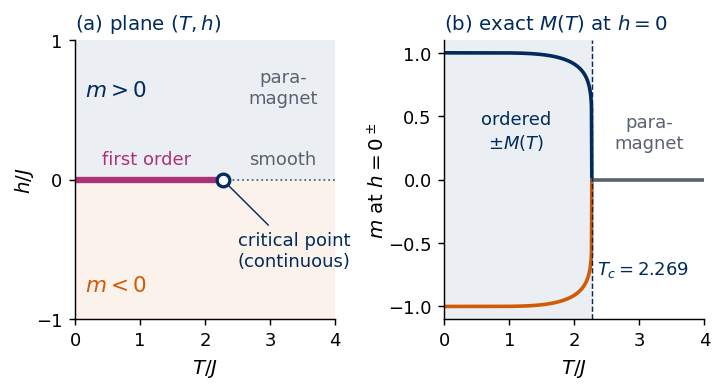

In [ ]:
# Schematic figure; this cell does not depend on any other cell of the notebook.
# Colour convention shared by all sketches of the course:
#   spin s = +1: filled navy disc,   spin s = -1: white disc with an orange rim;
#   satisfied bond: solid blue line, broken (frustrated) bond: dashed purple line marked with a cross.
# The figure is drawn at its physical size on a 16:9 slide (5.5 in = full text width) with 10-12 pt text,
# and shown here at a higher screen resolution.
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

NAVY, ORANGE, BLUE, GRAY, PURPLE, GREEN = "#002B5C", "#D35A05", "#005CA7", "#5A6270", "#AA3377", "#228833"
SKETCH_STYLE = {"font.size": 11, "axes.titlesize": 12, "axes.labelsize": 11, "xtick.labelsize": 10,
                "ytick.labelsize": 10, "legend.fontsize": 10, "figure.dpi": 130, "lines.linewidth": 1.5,
                "axes.spines.top": False, "axes.spines.right": False}

def save_sketch(fig, name, extra_dirs=()):
    # PNG copy for the lecture slides: white background, 300 dpi, included at its physical width
    os.makedirs("../beamer/figures", exist_ok=True)
    for d in ("../beamer/figures",) + tuple(d for d in extra_dirs if os.path.isdir(d)):
        fig.savefig(os.path.join(d, name), dpi=300, facecolor="white")

def sketch_ising_phase_diagram():
    Tc = 2.0 / np.log(1.0 + np.sqrt(2.0))                         # exact critical temperature (J = k_B = 1)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(5.5, 2.9))
    fig.subplots_adjust(left=0.1, right=0.98, bottom=0.16, top=0.9, wspace=0.42)

    # (a) the (T, h) plane: a first-order line on h = 0 that ends at the critical point
    ax1.fill_between([0, 4], 0, 1, color=NAVY, alpha=0.08, lw=0); ax1.fill_between([0, 4], -1, 0, color=ORANGE, alpha=0.08, lw=0)
    ax1.plot([0, Tc], [0, 0], color=PURPLE, lw=3.5, solid_capstyle="butt")
    ax1.plot([Tc, 4], [0, 0], color=GRAY, lw=1, ls=":")
    ax1.plot(Tc, 0, "o", ms=7, mfc="white", mec=NAVY, mew=1.8, zorder=5)
    ax1.text(0.15, 0.6, "$m>0$", fontsize=12, color=NAVY); ax1.text(0.15, -0.8, "$m<0$", fontsize=12, color=ORANGE)
    ax1.text(1.1, 0.08, "first order", fontsize=10, color=PURPLE, ha="center", va="bottom")
    ax1.text(3.2, 0.08, "smooth", fontsize=10, color=GRAY, ha="center", va="bottom")
    ax1.text(3.2, 0.55, "para-\nmagnet", fontsize=10, color=GRAY, ha="center")
    ax1.annotate("critical point\n(continuous)", xy=(Tc, 0), xytext=(2.5, -0.62), fontsize=10, color=NAVY, ha="left",
                 arrowprops=dict(arrowstyle="-", color=NAVY, lw=0.8))
    ax1.set_xlim(0, 4); ax1.set_ylim(-1, 1); ax1.set_xticks([0, 1, 2, 3, 4]); ax1.set_yticks([-1, 0, 1])
    ax1.set_xlabel("$T/J$"); ax1.set_ylabel("$h/J$", labelpad=0)
    ax1.set_title("(a) plane $(T,h)$", fontsize=11, color=NAVY, loc="left")

    # (b) the temperature axis at h = 0 with the exact spontaneous magnetisation of Onsager and Yang
    T = np.linspace(0.02, Tc, 400)
    M = np.clip(1.0 - np.sinh(2.0 / T) ** -4, 0, None) ** 0.125
    ax2.axvspan(0, Tc, color=NAVY, alpha=0.08, lw=0)
    ax2.plot(T, M, color=NAVY, lw=2); ax2.plot(T, -M, color=ORANGE, lw=2); ax2.plot([Tc, 4], [0, 0], color=GRAY, lw=2)
    ax2.axvline(Tc, color=NAVY, lw=0.8, ls="--")
    ax2.text(1.1, 0.25, "ordered\n$\\pm M(T)$", fontsize=10, color=NAVY, ha="center")
    ax2.text(3.15, 0.25, "para-\nmagnet", fontsize=10, color=GRAY, ha="center")
    ax2.text(Tc + 0.08, -0.75, f"$T_c={Tc:.3f}$", fontsize=10, color=NAVY)
    ax2.set_xlim(0, 4); ax2.set_ylim(-1.1, 1.1); ax2.set_xticks([0, 1, 2, 3, 4])
    ax2.set_xlabel("$T/J$"); ax2.set_ylabel("$m$ at $h=0^\\pm$", labelpad=0)
    ax2.set_title("(b) exact $M(T)$ at $h=0$", fontsize=11, color=NAVY, loc="left")
    return fig

with plt.rc_context(SKETCH_STYLE):
    fig = sketch_ising_phase_diagram()
save_sketch(fig, "sketch_ising_phases.png", extra_dirs=("../../Lecture_5/beamer/figures",))
plt.show()


<hr/>
## 8. Finite-size effects

A phase transition is a **non-analyticity** of $\ln Z$ (Lecture 4). For finite $N$, $Z$ is a finite sum of exponentials of $\beta$, an analytic
function, so **a finite lattice has no sharp transition**. What we see are *pseudo-critical* features — peaks of $c$ and $\chi$, the steepest drop of
$\langle|m|\rangle$ — whose positions $T^*(L)$ approach $T_c$ as $L\to\infty$ while the peaks grow.

The mechanism is the divergence of the correlation length $\xi(T)$ at $T_c$. On a lattice of size $L$ the critical behaviour is cut off when $\xi(T)\approx L$,
so the transition is rounded over a window that shrinks as $L$ grows. Since $\xi\sim|T-T_c|^{-\nu}$, the window is $|T-T_c|\sim L^{-1/\nu}$.
We test this by measuring $\chi(T)$ for $L=10, 20, 40$ on a fine grid around $T_c$, with a measurement after every sweep.

finite-size scan done in 71 s


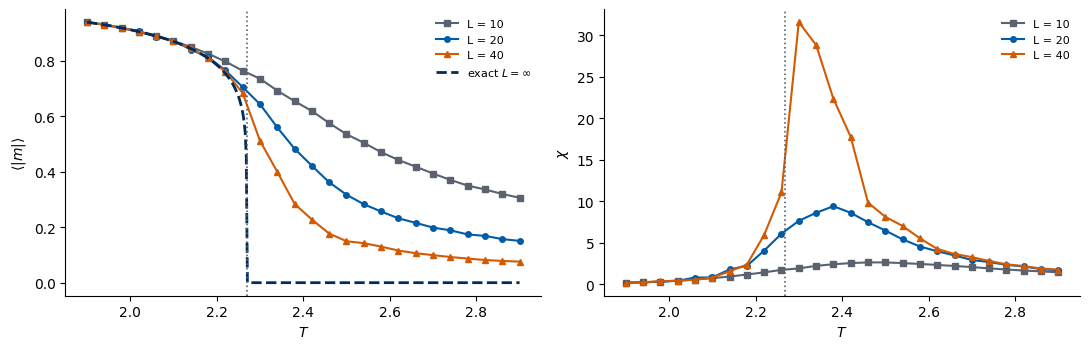

 L   T*(L) = argmax chi   chi_max    T*(L) - T_c
 10   2.46                  2.64    +0.191
 20   2.38                  9.42    +0.111
 40   2.30                 31.62    +0.031


In [11]:
def chi_scan(L, temps, n_chains, n_eq, n_meas, rng):
    # Measure <|m|> and chi on a temperature grid; measurements after every sweep (correlated, but averages are fine).
    masks = checkerboard_masks(L, L)
    beta = (1.0 / temps.astype(np.float32))[None, :, None, None]
    s = np.ones((n_chains, len(temps), L, L), np.float32)
    for _ in range(n_eq):
        metropolis_sweep(s, beta, masks, rng)
    m1, m2 = np.zeros(len(temps)), np.zeros(len(temps))
    for _ in range(n_meas):
        metropolis_sweep(s, beta, masks, rng)
        m = np.abs(magnetisation_per_spin(s))            # (chains, temps)
        m1 += m.mean(0); m2 += (m**2).mean(0)
    m1, m2 = m1 / n_meas, m2 / n_meas
    return m1, L * L * (m2 - m1**2) / temps

T_fs = np.round(np.arange(1.9, 2.9 + 1e-9, 0.04), 2)
fs = {}
t0 = time.time()
for L, nch in ((10, 32), (20, 16), (40, 8)):
    fs[L] = chi_scan(L, T_fs, n_chains=nch, n_eq=1000, n_meas=2000, rng=rng)
print(f"finite-size scan done in {time.time() - t0:.0f} s")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for (L, (m1, ch)), col, mk in zip(fs.items(), (UJGray, UJBlue, DSOrange), ("s", "o", "^")):
    axes[0].plot(T_fs, m1, "-" + mk, color=col, ms=4, label=f"L = {L}")
    axes[1].plot(T_fs, ch, "-" + mk, color=col, ms=4, label=f"L = {L}")
Tf2 = np.linspace(1.9, 2.9, 400)
axes[0].plot(Tf2, M_exact(Tf2), color=UJNavy, lw=2, ls="--", label=r"exact $L=\infty$")
for ax, lab in zip(axes, (r"$\langle|m|\rangle$", r"$\chi$")):
    ax.axvline(TC, color=UJGray, ls=":", lw=1.2); ax.set_xlabel("$T$"); ax.set_ylabel(lab); ax.legend(frameon=False, fontsize=8)
fig.tight_layout(); plt.show()

print(" L   T*(L) = argmax chi   chi_max    T*(L) - T_c")
for L, (m1, ch) in fs.items():
    i = np.argmax(ch)
    print(f"{L:3d}   {T_fs[i]:.2f}               {ch[i]:7.2f}    {T_fs[i] - TC:+.3f}")

As $L$ grows, the drop of $\langle|m|\rangle$ becomes steeper and approaches the exact curve, while the peak of $\chi$ grows (from $2.64$ to $31.62$) and moves toward
$T_c$ (from $T^*=2.46$ to $2.30$); the grid spacing $0.04$ limits the resolution of $T^*(L)$. *Locating* $T_c$ from finite data is therefore a **finite-size
extrapolation**, not a single measurement. The CNN in Lab 011 faces exactly the same limitation: its estimate $\bar T_c$ is a pseudo-critical temperature of an
$L\times L$ lattice. What the samples **do not** tell us is *why* there is a transition, or why it sits at $2/\ln(1+\sqrt2)$; that came from Onsager's exact solution (Lecture 4).
<hr/>
## 9. Exercises
1. Change `Nx, Ny` in Section 5 to a rectangular lattice, e.g. $40\times10$. How do the snapshots and $\langle|m|\rangle(T)$ change? (Hint: the shorter side limits $\xi$.)
2. Start the dataset from a **hot** start at all temperatures and repeat Section 7. Which temperatures are affected, and why?
3. Measure $\tau_{\rm int}$ at $T\approx T_c$ for $L=10,20,40$. How does it grow with $L$?
4. Implement the heat-bath (Glauber) rule $p(s_i=+1)=1/(1+e^{-2\beta\phi_i})$ instead of Metropolis, and check that the averages do not change.